# TRAJEtória — IA & Machine Learning

## Onde estão os jovens de 18 a 24 anos sem ensino médio completo?
### Um modelo municipal com dados públicos do Censo 2022 (IBGE)

**Global Solution 2026.2 · FIAP · Turma 3ESPH · Entrega de IA & Machine Learning**

| Integrante | RM | Turma |
|---|---|---|
| Enrico Ricarte (líder) | 558571 | 3ESPH |
| Pedro Gaspar | 554887 | 3ESPH |
| Victor Freire | 556191 | 3ESPH |

**CitizenTech:** TRAJEtória — plataforma social de redistribuição de roupas para jovens atendidos por ONGs.
**ODS:** 8 (principal), 10 (secundário) e 4 (recorte desta disciplina).
**Data:** novembro de 2026.

> **Como ler este notebook.** Ele está executado (Restart & Run All) e as saídas estão salvas. A coleta usa a API pública do IBGE e guarda um snapshot em `dados/raw/`, então o notebook também roda offline. Semente fixa (`SEMENTE = 42`) em todas as etapas aleatórias.

## 1. O problema e a decisão que o modelo precisa apoiar

A TRAJEtória conecta jovens em vulnerabilidade a roupas sociais doadas, com curadoria e entrega em casa. O piloto está definido em seus contornos gerais: um galpão em **São Caetano do Sul**, cerca de **40 entregas por mês** e um orçamento de logística de **R$ 1.000**. Falta a decisão mais concreta do ponto de vista operacional — registrada como pendência **Q03** na documentação funcional:

> **Em quais cidades, bairros e raio de entrega o piloto deve atuar?**

Essa decisão não é logística apenas. Ela define **quem será atendido**. Se o galpão está em São Caetano do Sul — um dos municípios mais ricos do ABC —, mas a vulnerabilidade juvenil se concentra nos municípios vizinhos, o raio de entrega precisa ser desenhado para alcançar quem de fato precisa, e não apenas quem está perto do galpão.

O Censo 2022 permite medir essa vulnerabilidade em cada um dos 5.570 municípios brasileiros. O que ele **não** entrega pronto é uma leitura priorizada: qual território concentra mais jovens na situação que a TRAJEtória quer atender, e quais características do território explicam essa concentração. É exatamente aí que entra o modelo.

## 2. A pergunta de Machine Learning

> **Quais municípios paulistas concentram mais jovens de 18 a 24 anos sem ensino médio completo, e quais características do território explicam essa concentração — para priorizar onde o piloto da TRAJEtória deve atuar?**

**Unidade de análise:** município (não o indivíduo).
**Variável-alvo:** proporção de jovens de 18 a 24 anos sem ensino médio completo (`taxa_sem_EM`).
**Features:** sete indicadores estruturais do território (escolaridade adulta, renda, internet, saneamento, cor/raça, urbanização e estrutura etária).
**Uso pretendido:** ranquear territórios, explicar os fatores associados e estimar o **número absoluto** de jovens sem ensino médio — o que orienta o raio de entrega e a escolha da ONG parceira.

### O que o modelo é e o que ele não é

| O modelo **é** | O modelo **não é** |
|---|---|
| Uma forma de aprender a relação entre características do território e vulnerabilidade educacional | Uma máquina de "descobrir" o Censo: o alvo já é publicado |
| Um instrumento de **priorização** e **explicação** | Uma prova de causalidade |
| Um score aplicável a recortes onde o indicador não está disponível | Uma previsão do futuro (o Censo é um retrato de 2022) |

**Critério de sucesso definido antes de treinar:** superar com folga os baselines (média e regressão linear) no conjunto de teste, manter a ordenação dos territórios (Spearman) alta o suficiente para uso em ranking e conseguir explicar os fatores em linguagem de cidadão.

## 3. Dados: por que o Censo 2022 e não os dados do aplicativo

A rubrica da disciplina exige **dados reais e públicos**. Duas bases do próprio projeto foram deliberadamente descartadas:

1. **`assets/mock/seed.json` do aplicativo.** O README do app e o próprio arquivo declaram que peças, jovens e pedidos são fictícios (`"Bairro Fictício"`, nomes inventados). Servem para demonstrar a interface, não para treinar modelo.
2. **A pesquisa com os 31 jovens.** É real, mas é uma amostra pequena, não pública e sem representatividade territorial. Entra no relatório como **motivação** (61,3% não sabem o que é adequado vestir; 54,8% já perderam uma entrevista por causa da roupa), nunca como base de treino.

A base usada é o **Censo Demográfico 2022**, agregado por município, obtido pela **API v3 do SIDRA** — sem download manual, com URL, data de coleta e hash registrados em `dados/README.md`.

| Tabela SIDRA | Variável | Para que serve | Papel |
|---|---|---|---|
| 10061 | 2667 | Pessoas de 18+ por nível de instrução e idade | **alvo** + `adultos_EM_mais` |
| 10296 | 13604 | Rendimento domiciliar per capita | `pct_baixa_renda` |
| 9936 | 381 | Domicílios com conexão à internet | `pct_internet` |
| 6805 | 381 | Tipo de esgotamento sanitário | `pct_esgoto_adequado` |
| 9605 | 93 | Cor ou raça | `pct_preta_parda` |
| 9923 | 93 | Situação do domicílio (urbana/rural) | `pct_urbana` |
| 9514 | 93 | População por idade | `pct_15_24` e população 18-24 |

**Cobertura:** 5.570 municípios, cobertura completa nas sete tabelas (nenhuma imputação foi necessária).

### 3.1 Coleta via API do IBGE

O módulo `src/ibge_api.py` monta a URL de cada agregado, baixa a resposta em JSON e grava o snapshot em `dados/raw/`. A partir da segunda execução o notebook lê o arquivo local — o que torna a entrega reprodutível e auditável mesmo que o IBGE mude algo.

Formato da chamada:

```
https://servicodados.ibge.gov.br/api/v3/agregados/{tabela}/periodos/2022/variaveis/{variavel}
    ?localidades=N6[all]&classificacao=...
```

`N6[all]` significa "todos os municípios do Brasil". As classificações foram restringidas às categorias que viram feature, o que reduz o tamanho da resposta sem perder informação.

In [1]:
%matplotlib inline

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# importa o pacote src/ tanto rodando de ml/ quanto da raiz do repositório
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd() / "ml"))

from src import ibge_api

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

SEMENTE = 42
DIR_FIG = ibge_api.DIR_ML / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

MUNICIPIOS_ABC = [
    "Santo André",
    "São Bernardo do Campo",
    "São Caetano do Sul",
    "Diadema",
    "Mauá",
    "Ribeirão Pires",
    "Rio Grande da Serra",
]

AZUL = "#1f4e79"
VERMELHO = "#c0392b"
CINZA = "#7f8c8d"
VERDE = "#2e7d32"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "figure.figsize": (9, 4.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

import sklearn

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print(f"Figuras em: {DIR_FIG}")
print(f"Semente global: {SEMENTE}")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1
Figuras em: C:\Users\errod\Desktop\GlobalSolution\MachineLearning\ml\figuras
Semente global: 42


In [2]:
resumo_coleta = ibge_api.baixar_todas()

exibicao = resumo_coleta[["tabela", "descricao", "origem", "bytes"]].copy()
exibicao["tamanho_MB"] = (exibicao.pop("bytes") / 1e6).round(2)
exibicao

,tabela,descricao,origem,tamanho_MB
0,10061,"Pessoas de 18 anos ou mais, por nível de instr...",cache local,7.55
1,10296,"Pessoas de 10 anos ou mais, por classes de ren...",cache local,9.03
2,9936,"Domicílios particulares permanentes ocupados, ...",cache local,2.27
3,6805,"Domicílios particulares permanentes ocupados, ...",cache local,7.51
4,9605,"População residente, por cor ou raça",cache local,4.53
5,9923,"População residente, por situação do domicílio",cache local,2.28
6,9514,"População residente, por sexo e idade",cache local,2.27


### 3.2 Da resposta bruta à base de municípios

O JSON do SIDRA vem aninhado (variável → resultado → classificação → série por localidade). O módulo achata isso em uma tabela *tidy* e depois combina as sete tabelas em **uma linha por município**, calculando as proporções.

Regras de tratamento, explicitadas para não maquiar dado:

* `...` (não disponível) e `X` (sigilo) viram `NaN`; `-` vira `0`;
* municípios sem alvo, sem população 18-24 ou sem alguma feature são **removidos**, não imputados;
* não há duplicidade de código IBGE;
* percentuais sempre no intervalo [0, 1].

In [3]:
base_bruta = ibge_api.construir_features()
df = ibge_api.tratar_dados(base_bruta)

df["nome"] = df["municipio"].str.rsplit(" - ", n=1).str[0]
df["regiao"] = "Fora de SP"
df.loc[df["uf"] == "SP", "regiao"] = "Demais municípios de SP"
df.loc[(df["uf"] == "SP") & df["nome"].isin(MUNICIPIOS_ABC), "regiao"] = "ABC paulista"
df.loc[(df["uf"] == "SP") & (df["nome"] == "São Paulo"), "regiao"] = "Capital"

print(f"Municípios na base: {len(df):,}")
print(f"Período: {ibge_api.PERIODO} | nível municipal (N6) | fonte: Censo 2022 / IBGE")
print(f"Municípios de São Paulo: {(df['uf'] == 'SP').sum()}")
print(f"Jovens de 18 a 24 anos na base: {df['pop_18_24'].sum():,.0f}")
df.head()

Municípios na base: 5,570
Período: 2022 | nível municipal (N6) | fonte: Censo 2022 / IBGE
Municípios de São Paulo: 645
Jovens de 18 a 24 anos na base: 21,201,469


,codigo,municipio,uf,pop_18_24,taxa_sem_EM,adultos_EM_mais,pct_baixa_renda,pct_internet,pct_esgoto_adequado,pct_preta_parda,pct_urbana,pct_15_24,nome,regiao
0,1100015,Alta Floresta D'Oeste - RO,RO,2157,0.598053,0.26732,0.311559,0.87349,0.189084,0.611426,0.603471,0.148786,Alta Floresta D'Oeste,Fora de SP
1,1100023,Ariquemes - RO,RO,11104,0.408051,0.445115,0.26194,0.890642,0.335711,0.672839,0.866977,0.165429,Ariquemes,Fora de SP
2,1100031,Cabixi - RO,RO,325,0.316923,0.334894,0.239895,0.918658,0.163701,0.598206,0.531863,0.116614,Cabixi,Fora de SP
3,1100049,Cacoal - RO,RO,10146,0.387148,0.436109,0.247538,0.913122,0.787762,0.604693,0.827592,0.157849,Cacoal,Fora de SP
4,1100056,Cerejeiras - RO,RO,1506,0.386454,0.426882,0.222595,0.906059,0.869402,0.604468,0.888357,0.138011,Cerejeiras,Fora de SP


In [4]:
resumo = df[["pop_18_24", ibge_api.ALVO, *ibge_api.FEATURES]].describe().T
resumo[["mean", "std", "min", "50%", "max"]].round(4)

,mean,std,min,50%,max
pop_18_24,3806.3679,20680.9967,56.0,1153.0,1129866.0
taxa_sem_EM,0.3983,0.1156,0.0411,0.3918,0.8484
adultos_EM_mais,0.3643,0.0983,0.1266,0.352,0.7716
pct_baixa_renda,0.3715,0.1917,0.0129,0.3297,0.8944
pct_internet,0.7958,0.091,0.2552,0.8099,0.969
pct_esgoto_adequado,0.5505,0.3125,0.0,0.5929,1.0
pct_preta_parda,0.5597,0.2269,0.0251,0.6079,0.972
pct_urbana,0.6904,0.2014,0.0733,0.7083,1.0
pct_15_24,0.1452,0.0219,0.077,0.1439,0.2335


In [5]:
caminho_features = ibge_api.salvar_processado(df)
print("Base processada salva em:", caminho_features)

Base processada salva em: C:\Users\errod\Desktop\GlobalSolution\MachineLearning\ml\dados\processed\municipios_features.csv


## 4. Análise exploratória

Antes de modelar, três perguntas: como o alvo se distribui, quais features andam junto com ele e como o ABC aparece nesse retrato.

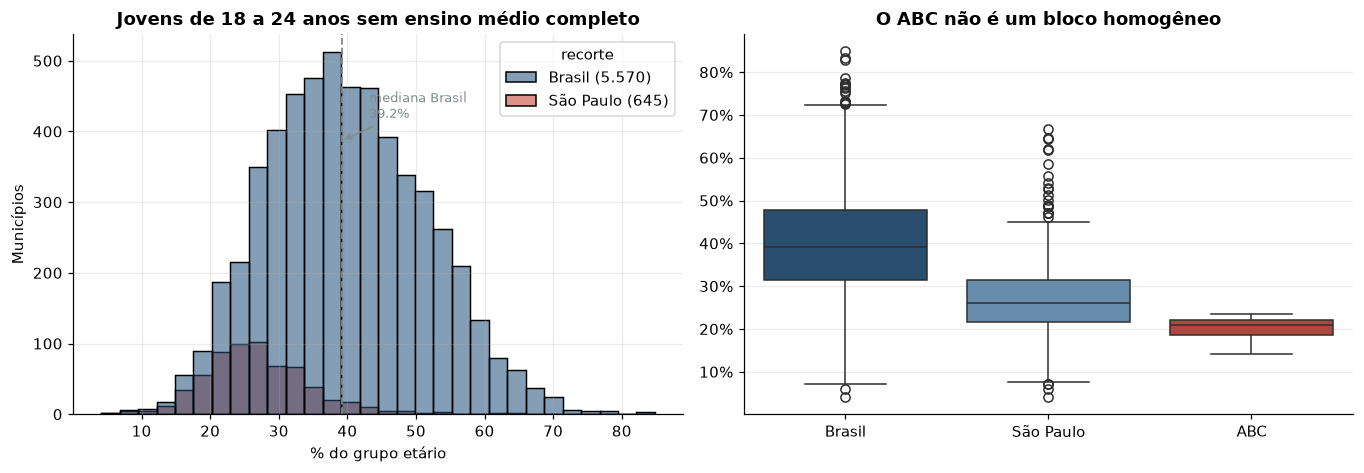

count    5570.0
mean     0.3983
std      0.1156
min      0.0411
25%      0.3133
50%      0.3918
75%      0.4776
max      0.8484


In [6]:
alvo = ibge_api.ALVO

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

dados_hist = pd.DataFrame({
    "taxa": np.concatenate([df[alvo] * 100, df.loc[df["uf"] == "SP", alvo] * 100]),
    "recorte": np.repeat(["Brasil (5.570)", "São Paulo (645)"],
                         [len(df), int((df["uf"] == "SP").sum())]),
})
sns.histplot(data=dados_hist, x="taxa", hue="recorte", bins=30,
             palette=[AZUL, VERMELHO], alpha=0.55, ax=axes[0])
mediana = df[alvo].median() * 100
axes[0].axvline(mediana, color=CINZA, ls="--", lw=1.2)
axes[0].annotate(f"mediana Brasil\n{mediana:.1f}%",
                 xy=(mediana, axes[0].get_ylim()[1] * 0.72),
                 xytext=(mediana + 4, axes[0].get_ylim()[1] * 0.78),
                 fontsize=8.5, color=CINZA,
                 arrowprops=dict(arrowstyle="->", color=CINZA, lw=1))
axes[0].set_title("Jovens de 18 a 24 anos sem ensino médio completo")
axes[0].set_xlabel("% do grupo etário")
axes[0].set_ylabel("Municípios")

grupos = pd.DataFrame({
    "taxa": np.concatenate([
        df[alvo].values,
        df.loc[df["uf"] == "SP", alvo].values,
        df.loc[df["regiao"] == "ABC paulista", alvo].values,
    ]),
    "grupo": np.repeat(
        ["Brasil", "São Paulo", "ABC"],
        [len(df), int((df["uf"] == "SP").sum()), int((df["regiao"] == "ABC paulista").sum())],
    ),
})
sns.boxplot(data=grupos, x="grupo", y="taxa", order=["Brasil", "São Paulo", "ABC"],
            palette=[AZUL, "#5b8db8", VERMELHO], ax=axes[1])
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:.0f}%"))
axes[1].set_title("O ABC não é um bloco homogêneo")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(DIR_FIG / "01_distribuicao_alvo.png", bbox_inches="tight")
plt.show()

print(df[alvo].describe().round(4).to_string())

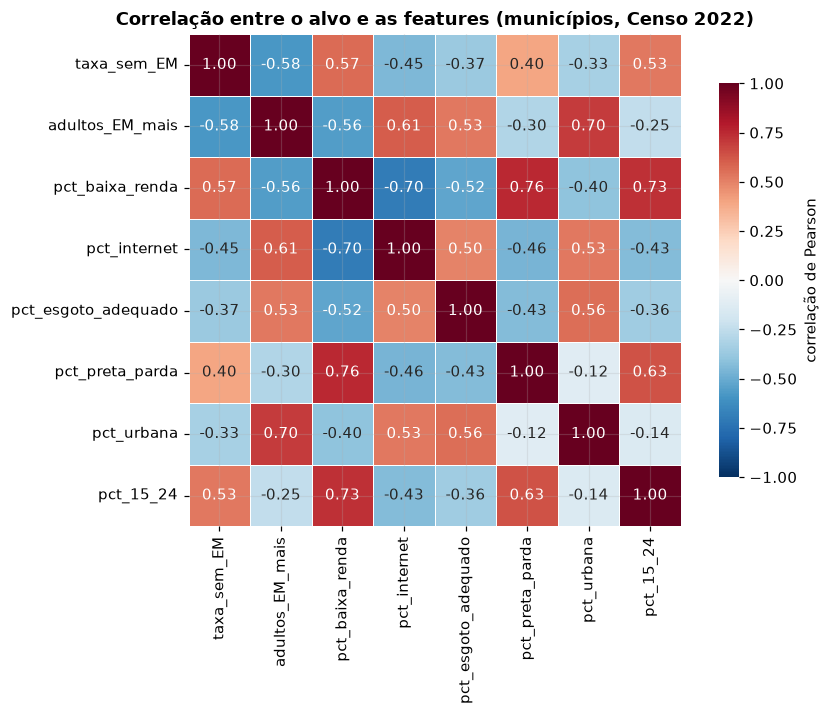

Correlação com o alvo (ordenada por magnitude):
adultos_EM_mais       -0.581
pct_baixa_renda        0.568
pct_15_24              0.527
pct_internet          -0.446
pct_preta_parda        0.398
pct_esgoto_adequado   -0.370
pct_urbana            -0.333


In [7]:
colunas_corr = [alvo, *ibge_api.FEATURES]
corr = df[colunas_corr].corr()

fig, ax = plt.subplots(figsize=(8.6, 6.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "correlação de Pearson"}, ax=ax)
ax.set_title("Correlação entre o alvo e as features (municípios, Censo 2022)")
plt.tight_layout()
plt.savefig(DIR_FIG / "02_correlacao.png", bbox_inches="tight")
plt.show()

print("Correlação com o alvo (ordenada por magnitude):")
print(corr[alvo].drop(alvo).sort_values(key=abs, ascending=False).round(3).to_string())

In [8]:
abc = df[df["regiao"] == "ABC paulista"].copy()
abc["jovens_sem_EM"] = (abc[alvo] * abc["pop_18_24"]).round().astype(int)
abc["taxa"] = abc[alvo].map("{:.1%}".format)
abc["adultos_EM_mais"] = abc["adultos_EM_mais"].map("{:.1%}".format)
abc["pct_baixa_renda"] = abc["pct_baixa_renda"].map("{:.1%}".format)

tabela_abc = (
    abc.sort_values(alvo)
    .loc[:, ["nome", "pop_18_24", "jovens_sem_EM", "taxa", "adultos_EM_mais", "pct_baixa_renda"]]
    .rename(columns={
        "nome": "Município",
        "pop_18_24": "População 18-24",
        "jovens_sem_EM": "Jovens sem EM",
        "taxa": "Taxa sem EM",
        "adultos_EM_mais": "Adultos com EM+",
        "pct_baixa_renda": "Baixa renda",
    })
)
tabela_abc

,Município,População 18-24,Jovens sem EM,Taxa sem EM,Adultos com EM+,Baixa renda
3812,São Caetano do Sul,12353,1754,14.2%,77.2%,7.5%
3753,Ribeirão Pires,11035,1876,17.0%,63.9%,20.8%
3801,Santo André,67078,13669,20.4%,68.5%,15.5%
3419,Diadema,42340,8868,20.9%,59.3%,22.4%
3761,Rio Grande da Serra,4776,1044,21.9%,58.3%,28.3%
3597,Mauá,43807,9703,22.1%,58.9%,22.6%
3811,São Bernardo do Campo,77463,18135,23.4%,67.7%,18.0%


A tabela acima já antecipa o achado central do projeto: **o galpão está no município menos vulnerável do ABC**. São Caetano do Sul tem a menor taxa de jovens sem ensino médio do grupo, enquanto Diadema, Mauá e São Bernardo do Campo concentram a maior parte dos jovens nessa situação. Se o piloto atender apenas o entorno imediato do galpão, vai atender quem menos precisa.

## 5. Preparação para a modelagem

**Split 80/20** com semente fixa, estratificado apenas pelo acaso (não há classes), mantendo a distribuição do alvo parecida entre treino e teste.

**Sem vazamento de dados:** nenhuma feature usa o alvo. As features vêm de outras tabelas do Censo (renda, saneamento, internet, cor/raça, urbanização, estrutura etária) ou de outro grupo etário da mesma tabela (escolaridade dos adultos 25+). O alvo é sempre o grupo de 18 a 24 anos — um recorte etário distinto do usado nas features de escolaridade.

**Peso amostral:** a população de 18 a 24 anos. Municípios minúsculos têm taxas instáveis (um município com 56 jovens pode oscilar 20 pontos percentuais com poucas pessoas), e sem peso o modelo persegue esse ruído.

In [9]:
from sklearn.model_selection import train_test_split

features = ibge_api.FEATURES

X = df[features].astype(float).copy()
y = df[alvo].astype(float).copy()
pesos = df["pop_18_24"].astype(float).copy()

X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(
    X, y, pesos, test_size=0.20, random_state=SEMENTE
)

print(f"Treino: {len(X_tr):,} municípios | Teste: {len(X_te):,} municípios")
print(f"Features ({len(features)}): {features}")
print(f"Média do alvo  -> treino {y_tr.mean():.3f} | teste {y_te.mean():.3f}")
print(f"Desvio do alvo -> treino {y_tr.std():.3f} | teste {y_te.std():.3f}")
print(f"Municípios no teste com menos de 500 jovens: {(w_te < 500).sum()}")

Treino: 4,456 municípios | Teste: 1,114 municípios
Features (7): ['adultos_EM_mais', 'pct_baixa_renda', 'pct_internet', 'pct_esgoto_adequado', 'pct_preta_parda', 'pct_urbana', 'pct_15_24']
Média do alvo  -> treino 0.398 | teste 0.399
Desvio do alvo -> treino 0.115 | teste 0.118
Municípios no teste com menos de 500 jovens: 280


## 6. Baselines: o que significa "ser melhor que o trivial"

Antes do Random Forest, dois referenciais:

* **Dummy (média do treino):** não aprende nada. Serve para provar que o modelo tem sinal.
* **Regressão Linear padronizada:** aprende uma relação linear entre as features e o alvo. É o baseline honesto — se o Random Forest não superar isso, a complexidade não se paga.

Métricas: **RMSE** e **MAE** (erro na proporção, quanto menor melhor), **R²** (quanto da variância o modelo explica) e **Spearman** (se a *ordenação* dos municípios é preservada — decisivo, porque o produto final é um ranking).

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr


def avaliar(nome, modelo, X_tr, y_tr, X_te, y_te):
    modelo.fit(X_tr, y_tr)
    linhas = []
    for conjunto, Xs, ys in [("treino", X_tr, y_tr), ("teste", X_te, y_te)]:
        previsto = modelo.predict(Xs)
        linhas.append({
            "modelo": nome,
            "conjunto": conjunto,
            "RMSE": mean_squared_error(ys, previsto) ** 0.5,
            "MAE": mean_absolute_error(ys, previsto),
            "R2": r2_score(ys, previsto),
            "Spearman": spearmanr(ys, previsto).statistic,
        })
    return pd.DataFrame(linhas)


def formatar(tabela):
    copia = tabela.copy()
    for coluna in ["RMSE", "MAE"]:
        copia[coluna] = copia[coluna].map("{:.4f}".format)
    for coluna in ["R2", "Spearman"]:
        copia[coluna] = copia[coluna].map("{:.3f}".format)
    return copia


tabela_base = pd.concat([
    avaliar("Média do treino (Dummy)", DummyRegressor(strategy="mean"), X_tr, y_tr, X_te, y_te),
    avaliar("Regressão Linear", make_pipeline(StandardScaler(), LinearRegression()), X_tr, y_tr, X_te, y_te),
], ignore_index=True)

formatar(tabela_base)

,modelo,conjunto,RMSE,MAE,R2,Spearman
0,Média do treino (Dummy),treino,0.1149,0.0929,0.000,nan
1,Média do treino (Dummy),teste,0.1182,0.0968,-0.000,nan
2,Regressão Linear,treino,0.0810,0.0645,0.503,0.704
3,Regressão Linear,teste,0.0837,0.0665,0.498,0.696


## 7. Random Forest com busca de hiperparâmetros

**Por que Random Forest:** a relação entre território e vulnerabilidade educacional não é linear nem aditiva (renda, saneamento e escolaridade dos adultos interagem). O Random Forest captura não linearidades e interações sem exigir engenharia manual, é robusto a outliers e a escalas diferentes, e oferece importância de variáveis — o que o relatório precisa para "explicar" o fenômeno. A literatura de políticas públicas também o usa com frequência justamente por esse equilíbrio entre desempenho e interpretabilidade.

**Busca em grade com 24 combinações** — todos os pares de três hiperparâmetros:

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `n_estimators` | 200, 400 | número de árvores (estabilidade) |
| `max_depth` | 4, 8, 12, sem limite | profundidade máxima (complexidade) |
| `min_samples_leaf` | 1, 3, 5 | mínimo de municípios por folha (suavização) |

**Validação cruzada 5-fold apenas no treino.** O teste fica intocado até a avaliação final — se a CV usasse o teste, o R² de teste deixaria de ser uma estimativa honesta de generalização. O critério de escolha é o menor RMSE médio na validação.

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold

grade = {
    "n_estimators": [200, 400],
    "max_depth": [4, 8, 12, None],
    "min_samples_leaf": [1, 3, 5],
}
print(f"Combinações de hiperparâmetros: {int(np.prod([len(v) for v in grade.values()]))}")

cv_treino = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)

busca = GridSearchCV(
    RandomForestRegressor(random_state=SEMENTE, n_jobs=-1),
    param_grid=grade,
    scoring="neg_root_mean_squared_error",
    cv=cv_treino,
    n_jobs=-1,
    return_train_score=True,
)
busca.fit(X_tr, y_tr)

resultados = pd.DataFrame(busca.cv_results_)
tabela_grade = pd.DataFrame({
    "n_estimators": resultados["param_n_estimators"].astype(int),
    "max_depth": resultados["param_max_depth"].astype(str).replace("None", "sem limite"),
    "min_samples_leaf": resultados["param_min_samples_leaf"].astype(int),
    "RMSE_CV_treino": -resultados["mean_train_score"],
    "RMSE_CV_validacao": -resultados["mean_test_score"],
    "desvio_CV": resultados["std_test_score"],
    "posicao": resultados["rank_test_score"].astype(int),
}).sort_values("posicao").reset_index(drop=True)

print(f"Combinações avaliadas: {len(tabela_grade)}")
tabela_grade.round(4)

Combinações de hiperparâmetros: 24


Combinações avaliadas: 24


,n_estimators,max_depth,min_samples_leaf,RMSE_CV_treino,RMSE_CV_validacao,desvio_CV,posicao
0,200,12,3,0.0467,0.0778,0.0016,1
1,400,12,3,0.0467,0.0779,0.0016,2
2,400,12,5,0.0528,0.0779,0.0015,3
3,200,12,5,0.0528,0.0779,0.0015,4
4,400,NaN,5,0.0508,0.0779,0.0016,5
5,200,NaN,5,0.0508,0.0779,0.0016,6
6,400,NaN,3,0.0414,0.0779,0.0016,7
7,200,NaN,3,0.0415,0.0779,0.0017,8
8,400,12,1,0.0412,0.0780,0.0016,9
9,200,12,1,0.0412,0.0780,0.0016,10


In [12]:
melhor_modelo = busca.best_estimator_
r2_cv_aproximado = 1 - (busca.best_score_ ** 2) / y_tr.var(ddof=0)

print("Melhor configuração pela validação cruzada (5-fold, só treino):")
print(f"  n_estimators     = {busca.best_params_['n_estimators']}")
print(f"  max_depth        = {busca.best_params_['max_depth']}")
print(f"  min_samples_leaf = {busca.best_params_['min_samples_leaf']}")
print(f"  RMSE_CV          = {-busca.best_score_:.4f}")
print(f"  desvio entre folds = {tabela_grade.loc[0, 'desvio_CV']:.4f}")
print(f"  R2 aproximado na validação = {r2_cv_aproximado:.3f}")

print()
print("Top 5 combinações:")
print(tabela_grade.head(5).round(4).to_string(index=False))

Melhor configuração pela validação cruzada (5-fold, só treino):
  n_estimators     = 200
  max_depth        = 12
  min_samples_leaf = 3
  RMSE_CV          = 0.0778
  desvio entre folds = 0.0016
  R2 aproximado na validação = 0.541

Top 5 combinações:
 n_estimators max_depth  min_samples_leaf  RMSE_CV_treino  RMSE_CV_validacao  desvio_CV  posicao
          200        12                 3          0.0467             0.0778     0.0016        1
          400        12                 3          0.0467             0.0779     0.0016        2
          400        12                 5          0.0528             0.0779     0.0015        3
          200        12                 5          0.0528             0.0779     0.0015        4
          400       NaN                 5          0.0508             0.0779     0.0016        5


## 8. Treino vs teste: a comparação que a rubrica pede

Agora o modelo escolhido é confrontado com o conjunto de teste, que ficou fechado desde o início. A tabela traz treino e teste lado a lado para os três modelos.

In [13]:
tabela_metricas = pd.concat([
    tabela_base,
    avaliar("Random Forest (melhor grid)", melhor_modelo, X_tr, y_tr, X_te, y_te),
], ignore_index=True)


def erro_ponderado(y_real, y_prev, pesos):
    y_real = np.asarray(y_real, dtype=float)
    y_prev = np.asarray(y_prev, dtype=float)
    pesos = np.asarray(pesos, dtype=float)
    rmse = float(np.sqrt(np.average((y_real - y_prev) ** 2, weights=pesos)))
    mae = float(np.average(np.abs(y_real - y_prev), weights=pesos))
    media = np.average(y_real, weights=pesos)
    r2 = float(1 - np.average((y_real - y_prev) ** 2, weights=pesos)
               / np.average((y_real - media) ** 2, weights=pesos))
    return rmse, mae, r2


previsto_te = melhor_modelo.predict(X_te)
rmse_w, mae_w, r2_w = erro_ponderado(y_te, previsto_te, w_te)

linha_rf = tabela_metricas.query("modelo == 'Random Forest (melhor grid)' and conjunto == 'teste'").iloc[0]
linha_lin = tabela_metricas.query("modelo == 'Regressão Linear' and conjunto == 'teste'").iloc[0]

print("Métricas ponderadas pela população de 18 a 24 anos (teste):")
print(f"  RMSE = {rmse_w:.4f} | MAE = {mae_w:.4f} | R2 = {r2_w:.3f}")
print()
print(f"Ganho de R2 no teste sobre a Regressão Linear: {linha_rf['R2'] - linha_lin['R2']:+.3f}")
print(f"Ganho de R2 no teste sobre a média (Dummy):    {linha_rf['R2']:+.3f}")
print()
formatar(tabela_metricas.sort_values(["modelo", "conjunto"]))

Métricas ponderadas pela população de 18 a 24 anos (teste):
  RMSE = 0.0653 | MAE = 0.0485 | R2 = 0.674

Ganho de R2 no teste sobre a Regressão Linear: +0.035
Ganho de R2 no teste sobre a média (Dummy):    +0.534



,modelo,conjunto,RMSE,MAE,R2,Spearman
1,Média do treino (Dummy),teste,0.1182,0.0968,-0.000,nan
0,Média do treino (Dummy),treino,0.1149,0.0929,0.000,nan
5,Random Forest (melhor grid),teste,0.0807,0.0629,0.534,0.721
4,Random Forest (melhor grid),treino,0.0479,0.0373,0.826,0.914
3,Regressão Linear,teste,0.0837,0.0665,0.498,0.696
2,Regressão Linear,treino,0.0810,0.0645,0.503,0.704


In [14]:
serie_prevista = pd.Series(previsto_te, index=X_te.index)
top20_real = set(y_te.nlargest(20).index)
top20_previsto = set(serie_prevista.nlargest(20).index)

print(f"Municípios do top 20 real que também aparecem no top 20 previsto: {len(top20_real & top20_previsto)}/20")
print(f"Spearman no teste: {linha_rf['Spearman']:.3f} — a ordenação geral se mantém")
print()
print("A leitura honesta: o modelo ordena bem o conjunto (Spearman alto), mas erra mais")
print("nos extremos. Os 20 municípios com maior taxa real são cidades pequenas, com")
print("poucos jovens e taxas instáveis — justamente por isso a prioridade operacional")
print("usa o volume absoluto, e não a taxa isolada.")

Municípios do top 20 real que também aparecem no top 20 previsto: 7/20
Spearman no teste: 0.721 — a ordenação geral se mantém

A leitura honesta: o modelo ordena bem o conjunto (Spearman alto), mas erra mais
nos extremos. Os 20 municípios com maior taxa real são cidades pequenas, com
poucos jovens e taxas instáveis — justamente por isso a prioridade operacional
usa o volume absoluto, e não a taxa isolada.


## 9. Overfitting: onde a complexidade deixa de valer a pena

Um Random Forest sem limite de profundidade decora o treino. A curva abaixo varia a profundidade mantendo o resto fixo e mostra três R²: treino, validação cruzada (só no treino) e teste.

O padrão esperado — e o que a rubrica quer ver discutido — é o **gap crescente** entre treino e generalização. Um R² de treino de 0,95 com teste de 0,50 não é um bom modelo: é um modelo que memorizou 5.570 municípios e não aprendeu a regra.

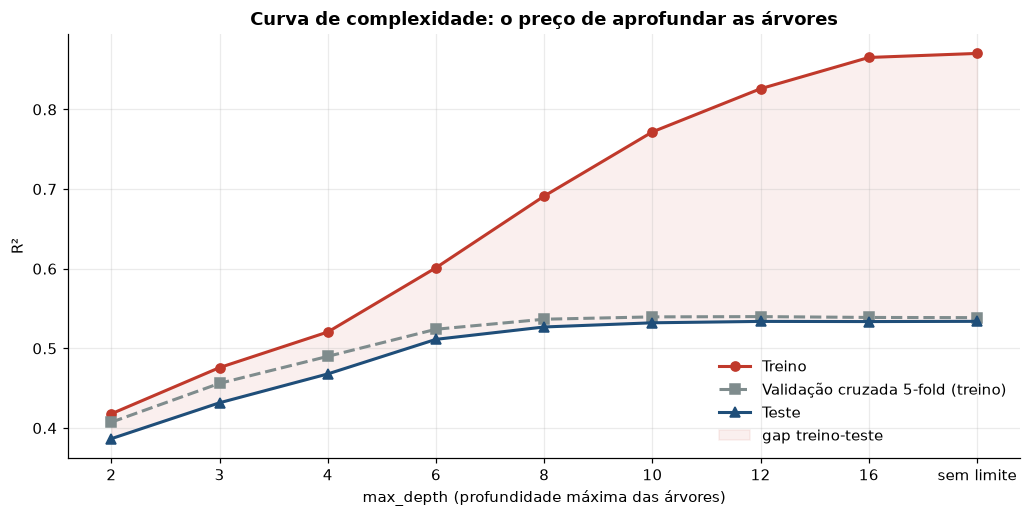

,profundidade,R2_treino,R2_validacao,R2_teste
0,2,0.418,0.407,0.387
1,3,0.476,0.456,0.432
2,4,0.521,0.490,0.468
3,6,0.601,0.524,0.511
4,8,0.691,0.537,0.527
5,10,0.772,0.540,0.532
6,12,0.826,0.540,0.534
7,16,0.865,0.539,0.534
8,sem limite,0.870,0.539,0.534


In [15]:
from sklearn.model_selection import cross_val_score

profundidades = [2, 3, 4, 6, 8, 10, 12, 16, None]
linhas_curva = []

for profundidade in profundidades:
    modelo = RandomForestRegressor(
        n_estimators=200,
        max_depth=profundidade,
        min_samples_leaf=3,
        random_state=SEMENTE,
        n_jobs=-1,
    )
    modelo.fit(X_tr, y_tr)
    cv = cross_val_score(modelo, X_tr, y_tr, cv=cv_treino, scoring="r2", n_jobs=-1)
    linhas_curva.append({
        "profundidade": "sem limite" if profundidade is None else str(profundidade),
        "R2_treino": r2_score(y_tr, modelo.predict(X_tr)),
        "R2_validacao": cv.mean(),
        "R2_teste": r2_score(y_te, modelo.predict(X_te)),
    })

curva = pd.DataFrame(linhas_curva)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(curva["profundidade"], curva["R2_treino"], marker="o", lw=2,
        color=VERMELHO, label="Treino")
ax.plot(curva["profundidade"], curva["R2_validacao"], marker="s", lw=2,
        color=CINZA, ls="--", label="Validação cruzada 5-fold (treino)")
ax.plot(curva["profundidade"], curva["R2_teste"], marker="^", lw=2,
        color=AZUL, label="Teste")
ax.fill_between(range(len(curva)), curva["R2_teste"], curva["R2_treino"],
                color=VERMELHO, alpha=0.08, label="gap treino-teste")
ax.set_xlabel("max_depth (profundidade máxima das árvores)")
ax.set_ylabel("R²")
ax.set_title("Curva de complexidade: o preço de aprofundar as árvores")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig(DIR_FIG / "03_curva_complexidade.png", bbox_inches="tight")
plt.show()

curva.round(3)

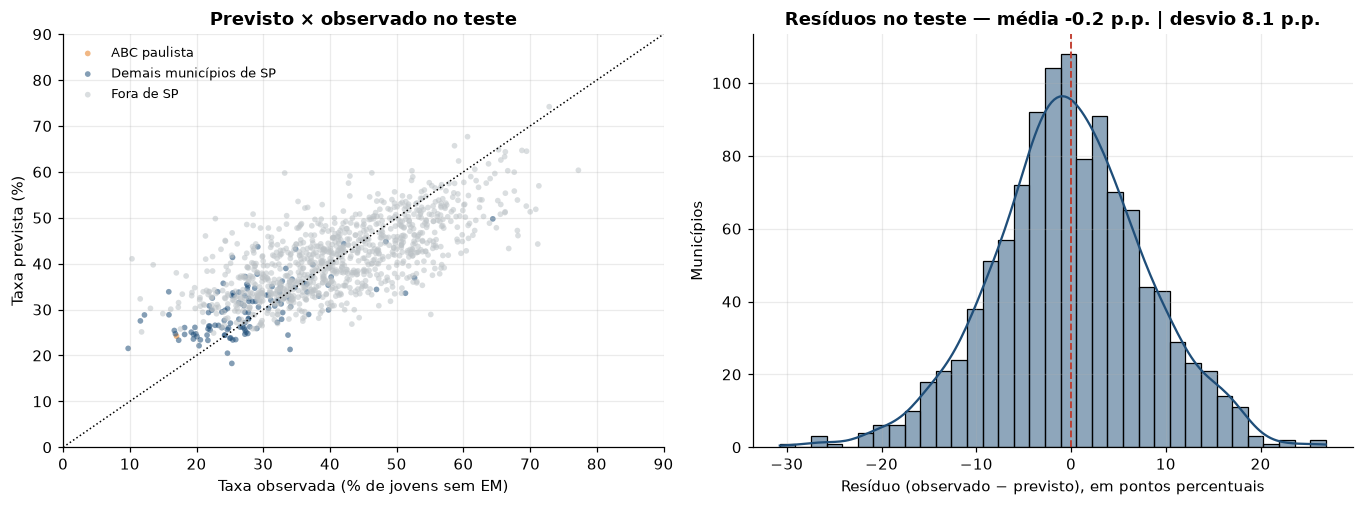

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.7))

cores_regiao = {"Capital": VERMELHO, "ABC paulista": "#e67e22", "Demais municípios de SP": AZUL, "Fora de SP": "#bdc3c7"}
for regiao, cor in cores_regiao.items():
    mascara = df.loc[X_te.index, "regiao"] == regiao
    if mascara.any():
        axes[0].scatter(y_te[mascara] * 100, serie_prevista[mascara] * 100,
                        s=14, alpha=0.55, color=cor, label=regiao, edgecolors="none")
limites = [0, 90]
axes[0].plot(limites, limites, color="black", lw=1, ls=":")
axes[0].set_xlim(limites)
axes[0].set_ylim(limites)
axes[0].set_xlabel("Taxa observada (% de jovens sem EM)")
axes[0].set_ylabel("Taxa prevista (%)")
axes[0].set_title("Previsto × observado no teste")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")

residuos = (y_te - serie_prevista) * 100
sns.histplot(residuos, bins=35, color=AZUL, ax=axes[1], kde=True)
axes[1].axvline(0, color=VERMELHO, lw=1.2, ls="--")
axes[1].set_xlabel("Resíduo (observado − previsto), em pontos percentuais")
axes[1].set_ylabel("Municípios")
axes[1].set_title(f"Resíduos no teste — média {residuos.mean():+.1f} p.p. | desvio {residuos.std():.1f} p.p.")

plt.tight_layout()
plt.savefig(DIR_FIG / "04_previsto_vs_observado.png", bbox_inches="tight")
plt.show()

## 10. O que o modelo aprendeu

A importância por permutação mede o quanto o R² cai quando uma feature é embaralhada **no conjunto de teste**. É mais honesta que a importância "impurity-based" do Random Forest, que superestima variáveis contínuas e de alta cardinalidade.

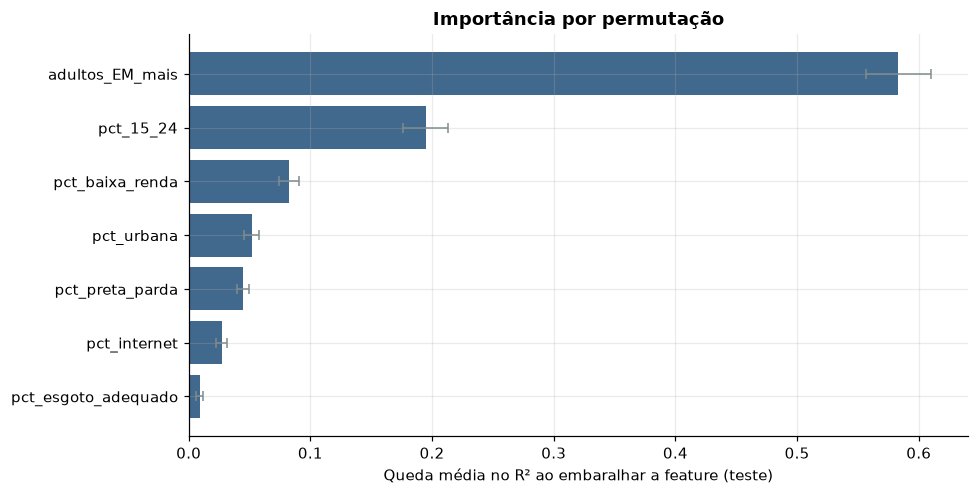

,feature,importancia,desvio
0,adultos_EM_mais,0.5832,0.0267
6,pct_15_24,0.1947,0.0185
1,pct_baixa_renda,0.0825,0.0083
5,pct_urbana,0.0516,0.0061
4,pct_preta_parda,0.0443,0.0050
2,pct_internet,0.0270,0.0047
3,pct_esgoto_adequado,0.0089,0.0026


In [17]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    melhor_modelo, X_te, y_te,
    n_repeats=20, random_state=SEMENTE, n_jobs=-1, scoring="r2",
)
importancia = (
    pd.DataFrame({
        "feature": features,
        "importancia": perm.importances_mean,
        "desvio": perm.importances_std,
    })
    .sort_values("importancia")
)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(importancia["feature"], importancia["importancia"],
        xerr=importancia["desvio"], color=AZUL, alpha=0.85,
        error_kw=dict(ecolor=CINZA, lw=1, capsize=3))
ax.set_xlabel("Queda média no R² ao embaralhar a feature (teste)")
ax.set_title("Importância por permutação")
plt.tight_layout()
plt.savefig(DIR_FIG / "05_importancia_permutacao.png", bbox_inches="tight")
plt.show()

importancia.sort_values("importancia", ascending=False).round(4)

## 11. Leitura para o cidadão: onde o piloto deve atuar

O modelo é aplicado aos **645 municípios paulistas** e gera a entrega operacional do projeto: uma lista priorizada com as informações que o time consegue usar na segunda-feira seguinte.

**Como a prioridade é calculada.** O critério é o **volume estimado de jovens sem ensino médio completo** (`taxa prevista × população de 18 a 24 anos`), expresso como percentil de 0 a 100. A escolha é deliberada:

* o piloto tem **40 entregas por mês** e orçamento de logística fixo — o que dimensiona a operação é o **número de jovens**, não a taxa;
* um município com 60% de evasão e 300 jovens é urgente para quem já atua nele, mas não sustenta a abertura de uma praça de entrega;
* a **taxa** continua na tabela como lente de intensidade, útil para decidir *dentro* de um raio já escolhido.

`nivel_prioridade` resume o percentil: **Alta** = top 10% em volume, **Média** = até o percentil 66, **Baixa** = restante. `posicao_volume` dá a posição explícita (1 = maior volume do estado).

In [18]:
sp = df[df["uf"] == "SP"].copy()
sp["taxa_prevista"] = np.clip(melhor_modelo.predict(sp[features]), 0, 1)
sp["jovens_sem_EM_estimado"] = sp["taxa_prevista"] * sp["pop_18_24"]

# prioridade = percentil do volume estimado (0 a 100); posicao_volume = 1 é o maior do estado
sp["prioridade"] = (sp["jovens_sem_EM_estimado"].rank(pct=True) * 100).round(1)
sp["posicao_volume"] = sp["jovens_sem_EM_estimado"].rank(ascending=False, method="min").astype(int)
sp["nivel_prioridade"] = np.select(
    [sp["prioridade"] >= 90, sp["prioridade"] >= 66.6],
    ["Alta", "Média"],
    default="Baixa",
)

prioridade_sp = pd.DataFrame({
    "codigo_ibge": sp["codigo"],
    "municipio": sp["nome"],
    "regiao": sp["regiao"],
    "pop_18_24": sp["pop_18_24"].astype(int),
    "taxa_observada": sp[alvo].round(4),
    "taxa_prevista": sp["taxa_prevista"].round(4),
    "jovens_sem_EM_estimado": sp["jovens_sem_EM_estimado"].round().astype(int),
    "posicao_volume": sp["posicao_volume"],
    "prioridade": sp["prioridade"],
    "nivel_prioridade": sp["nivel_prioridade"],
}).sort_values("posicao_volume").reset_index(drop=True)

caminho_prioridade = ibge_api.DIR_PROCESSED / "prioridade_sp.csv"
prioridade_sp.to_csv(caminho_prioridade, index=False, encoding="utf-8")
print(f"Arquivo gerado: {caminho_prioridade}")
print(f"Municípios priorizados: {len(prioridade_sp)}")

top15 = prioridade_sp.head(15).copy()
top15["taxa_prevista"] = top15["taxa_prevista"].map("{:.1%}".format)
top15["taxa_observada"] = top15["taxa_observada"].map("{:.1%}".format)
top15

Arquivo gerado: C:\Users\errod\Desktop\GlobalSolution\MachineLearning\ml\dados\processed\prioridade_sp.csv
Municípios priorizados: 645


,codigo_ibge,municipio,regiao,pop_18_24,taxa_observada,taxa_prevista,jovens_sem_EM_estimado,posicao_volume,prioridade,nivel_prioridade
0,3550308,São Paulo,Capital,1129866,26.4%,25.8%,291410,1,100.0,Alta
1,3518800,Guarulhos,Demais municípios de SP,137636,26.6%,26.2%,36032,2,99.8,Alta
2,3509502,Campinas,Demais municípios de SP,108202,25.0%,23.8%,25706,3,99.7,Alta
3,3534401,Osasco,Demais municípios de SP,72388,24.6%,25.6%,18555,4,99.5,Alta
4,3543402,Ribeirão Preto,Demais municípios de SP,69665,28.0%,26.1%,18176,5,99.4,Alta
5,3548708,São Bernardo do Campo,ABC paulista,77463,23.4%,23.1%,17910,6,99.2,Alta
6,3549904,São José dos Campos,Demais municípios de SP,67933,21.7%,23.3%,15819,7,99.1,Alta
7,3552205,Sorocaba,Demais municípios de SP,70934,20.2%,22.0%,15629,8,98.9,Alta
8,3547809,Santo André,ABC paulista,67078,20.4%,22.9%,15392,9,98.8,Alta
9,3523107,Itaquaquecetuba,Demais municípios de SP,42080,27.3%,31.1%,13065,10,98.6,Alta


In [19]:
abc_previsto = (
    prioridade_sp[prioridade_sp["regiao"] == "ABC paulista"]
    .sort_values("posicao_volume")
    .copy()
)
abc_previsto["taxa_prevista"] = abc_previsto["taxa_prevista"].map("{:.1%}".format)
abc_previsto["taxa_observada"] = abc_previsto["taxa_observada"].map("{:.1%}".format)

print("ABC paulista — o território do galpão:")
display(abc_previsto)

print()
capital = prioridade_sp[prioridade_sp["municipio"] == "São Paulo"].iloc[0]
galpao = prioridade_sp[prioridade_sp["municipio"] == "São Caetano do Sul"].iloc[0]
print(f"São Paulo (capital): {capital['pop_18_24']:,} jovens de 18-24 | "
      f"taxa prevista {capital['taxa_prevista']:.1%} | "
      f"~{capital['jovens_sem_EM_estimado']:,} jovens sem EM | "
      f"{capital['posicao_volume']}º do estado em volume")
print(f"São Caetano do Sul (galpão): taxa prevista {galpao['taxa_prevista']:.1%} | "
      f"~{galpao['jovens_sem_EM_estimado']:,} jovens sem EM | "
      f"{galpao['posicao_volume']}º do estado em volume ({galpao['nivel_prioridade']})")

ABC paulista — o território do galpão:


,codigo_ibge,municipio,regiao,pop_18_24,taxa_observada,taxa_prevista,jovens_sem_EM_estimado,posicao_volume,prioridade,nivel_prioridade
5,3548708,São Bernardo do Campo,ABC paulista,77463,23.4%,23.1%,17910,6,99.2,Alta
8,3547809,Santo André,ABC paulista,67078,20.4%,22.9%,15392,9,98.8,Alta
12,3529401,Mauá,ABC paulista,43807,22.1%,25.7%,11255,13,98.1,Alta
15,3513801,Diadema,ABC paulista,42340,20.9%,24.6%,10407,16,97.7,Alta
72,3543303,Ribeirão Pires,ABC paulista,11035,17.0%,24.2%,2672,73,88.8,Média
78,3548807,São Caetano do Sul,ABC paulista,12353,14.2%,20.1%,2482,79,87.9,Média
147,3544103,Rio Grande da Serra,ABC paulista,4776,21.9%,25.5%,1220,148,77.2,Média



São Paulo (capital): 1,129,866 jovens de 18-24 | taxa prevista 25.8% | ~291,410 jovens sem EM | 1º do estado em volume
São Caetano do Sul (galpão): taxa prevista 20.1% | ~2,482 jovens sem EM | 79º do estado em volume (Média)


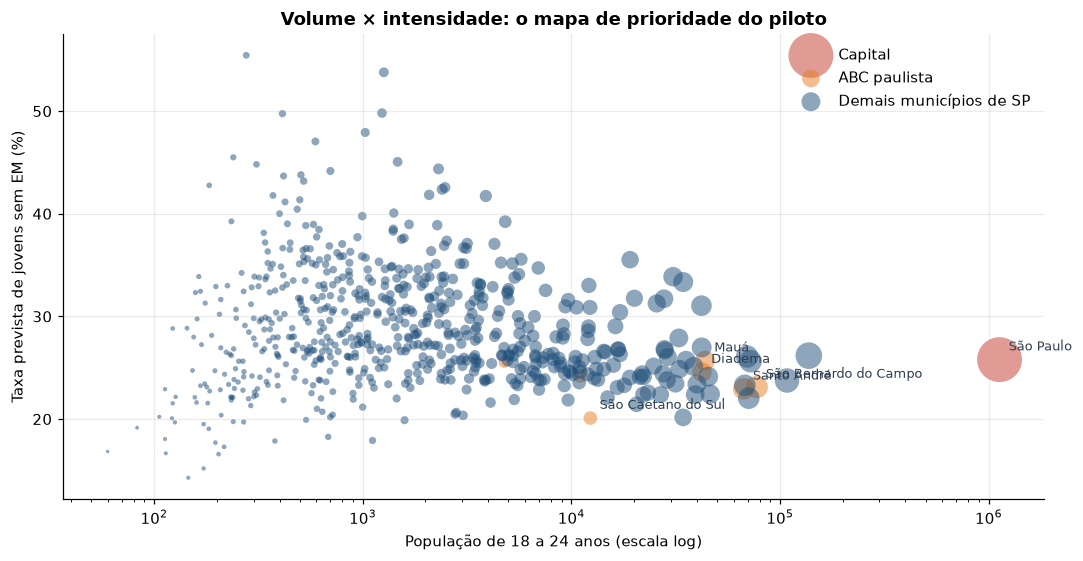

,municipios,jovens_18_24,jovens_sem_EM,taxa_media
regiao,,,,
Demais municípios de SP,637,2952513,789468.475355,0.289
Capital,1,1129866,291409.531099,0.258
ABC paulista,7,258852,61338.248127,0.237


In [20]:
fig, ax = plt.subplots(figsize=(10, 5.2))

cores = {"Capital": VERMELHO, "ABC paulista": "#e67e22", "Demais municípios de SP": AZUL}
for regiao, cor in cores.items():
    dados_regiao = sp[sp["regiao"] == regiao]
    ax.scatter(
        dados_regiao["pop_18_24"], dados_regiao["taxa_prevista"] * 100,
        s=np.sqrt(dados_regiao["jovens_sem_EM_estimado"]) * 1.6,
        alpha=0.5, color=cor, edgecolors="none", label=regiao,
    )

destaques = ["São Paulo", "São Caetano do Sul", "Diadema", "Mauá",
             "São Bernardo do Campo", "Santo André"]
for nome in destaques:
    linha = sp[sp["nome"] == nome]
    if linha.empty:
        continue
    ax.annotate(
        nome,
        xy=(linha["pop_18_24"].iloc[0], linha["taxa_prevista"].iloc[0] * 100),
        xytext=(6, 6), textcoords="offset points", fontsize=8.5, color="#2c3e50",
    )

ax.set_xscale("log")
ax.set_xlabel("População de 18 a 24 anos (escala log)")
ax.set_ylabel("Taxa prevista de jovens sem EM (%)")
ax.set_title("Volume × intensidade: o mapa de prioridade do piloto")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(DIR_FIG / "06_volume_vs_intensidade.png", bbox_inches="tight")
plt.show()

resumo_regiao = (
    sp.groupby("regiao")
    .agg(municipios=("codigo", "count"),
         jovens_18_24=("pop_18_24", "sum"),
         jovens_sem_EM=("jovens_sem_EM_estimado", "sum"),
         taxa_media=("taxa_prevista", "mean"))
    .round({"taxa_media": 3})
    .sort_values("jovens_sem_EM", ascending=False)
)
resumo_regiao

## 12. Conclusão, limitações e próximos passos

### O que o modelo entrega

* um **ranking municipal** de prioridade para o piloto (`dados/processed/prioridade_sp.csv`);
* uma **explicação** dos fatores associados à vulnerabilidade (importância por permutação);
* uma **estimativa de volume** (jovens sem EM), que é o número que dimensiona a operação — e não apenas a taxa, que favorece municípios minúsculos.

### A leitura para o cidadão

O galpão da TRAJEtória está em **São Caetano do Sul**, o município menos vulnerável do ABC — e fica fora do grupo de maior prioridade do estado. Já **São Bernardo do Campo** e **Santo André** aparecem entre os dez municípios paulistas com maior volume de jovens sem ensino médio completo, e a **capital** concentra o maior contingente absoluto do estado. Isso significa que:

1. o raio de entrega precisa **ultrapassar o entorno do galpão** — com custo por entrega, o piloto deve desenhar um recorte que alcance os municípios vizinhos de maior volume;
2. a **ONG parceira** deve ser escolhida pela capilaridade no território de maior prioridade, não pela proximidade do galpão;
3. o discurso do projeto fica verificável: não é "achismo" sobre onde estão os jovens, é Censo 2022 com um modelo que ranqueia e explica.

### Limitações (para constar no relatório)

* **Falácia ecológica:** o dado é municipal. O modelo fala do território, não do jovem individual. Não se pode concluir que todo jovem de um município vulnerável precisa do serviço.
* **Censo 2022 é um retrato**, não uma previsão. O modelo não antecipa mudanças econômicas ou demográficas.
* **Não é causal:** as associações não provam que renda ou saneamento causem evasão escolar. Servem para priorizar e levantar hipóteses.
* **Municípios pequenos:** a taxa é instável (um município com 56 jovens oscila muito), e o modelo tende a **puxar os extremos para o meio** — São Caetano do Sul, por exemplo, tem taxa observada bem abaixo da prevista. Por isso a entrega operacional mantém a coluna **observada** ao lado da prevista.
* **O alvo já é publicado:** o valor do modelo não está em "descobrir" o Censo, e sim em explicar os fatores associados, ranquear com um critério transparente e aplicar o score a recortes onde o indicador não está disponível.
* **Gap treino-teste:** o R² de treino é bem maior que o de teste. É o comportamento esperado em um modelo de árvores com profundidade 12 e mostra que a maior parte do ganho vem da estrutura não linear, mas há memorização — controlada pelo limite de profundidade e pelo `min_samples_leaf`.

### Próximos passos

1. Validar o ranking com a ONG parceira (a lista prioriza; a realidade de campo confirma).
2. Refinar para **setores censitários** ou bairros da capital, onde a decisão de raio acontece de fato.
3. Incorporar dados de **empregabilidade jovem** (PNAD Contínua) para aproximar o alvo da dor relatada na pesquisa: a entrevista de emprego.

In [21]:
print("=" * 74)
print("RESUMO AUTOMÁTICO DA EXECUÇÃO")
print("=" * 74)
print(f"Base............: {len(df):,} municípios | Censo 2022 / IBGE (API SIDRA v3)")
print(f"Treino / teste..: {len(X_tr):,} / {len(X_te):,} municípios (80/20, semente {SEMENTE})")
print(f"Features........: {len(features)}")
print(f"Grid............: {len(tabela_grade)} combinações de 3 hiperparâmetros")
print(f"Melhor modelo...: {busca.best_params_}")
print()
r2_treino = r2_score(y_tr, melhor_modelo.predict(X_tr))
r2_teste = r2_score(y_te, previsto_te)
print(f"R2 treino.......: {r2_treino:.3f}")
print(f"R2 teste........: {r2_teste:.3f}")
print(f"Gap treino-teste: {r2_treino - r2_teste:.3f}")
print(f"RMSE teste......: {np.sqrt(mean_squared_error(y_te, previsto_te)):.4f} "
      f"({np.sqrt(mean_squared_error(y_te, previsto_te))*100:.1f} pontos percentuais)")
print(f"Spearman teste..: {spearmanr(y_te, previsto_te).statistic:.3f}")
print()
print("Top 5 municípios por prioridade (SP):")
for posicao, (_, linha) in enumerate(prioridade_sp.head(5).iterrows(), start=1):
    print(f"  {posicao}. {linha['municipio']:<24} prioridade {linha['prioridade']:5.1f} | "
          f"{linha['taxa_prevista']:.1%} | ~{linha['jovens_sem_EM_estimado']:,} jovens sem EM")
print()
print(f"São Caetano do Sul (galpão): {galpao['posicao_volume']}º de 645 em volume de jovens sem EM "
      f"({galpao['nivel_prioridade']}) | taxa prevista {galpao['taxa_prevista']}")
print()
print("Arquivos gerados:")
print(f"  - {caminho_features}")
print(f"  - {caminho_prioridade}")
print(f"  - figuras em {DIR_FIG}")
print("=" * 74)

RESUMO AUTOMÁTICO DA EXECUÇÃO
Base............: 5,570 municípios | Censo 2022 / IBGE (API SIDRA v3)
Treino / teste..: 4,456 / 1,114 municípios (80/20, semente 42)
Features........: 7
Grid............: 24 combinações de 3 hiperparâmetros
Melhor modelo...: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 200}

R2 treino.......: 0.826
R2 teste........: 0.534
Gap treino-teste: 0.292
RMSE teste......: 0.0807 (8.1 pontos percentuais)
Spearman teste..: 0.721

Top 5 municípios por prioridade (SP):
  1. São Paulo                prioridade 100.0 | 25.8% | ~291,410 jovens sem EM
  2. Guarulhos                prioridade  99.8 | 26.2% | ~36,032 jovens sem EM
  3. Campinas                 prioridade  99.7 | 23.8% | ~25,706 jovens sem EM
  4. Osasco                   prioridade  99.5 | 25.6% | ~18,555 jovens sem EM
  5. Ribeirão Preto           prioridade  99.4 | 26.1% | ~18,176 jovens sem EM

São Caetano do Sul (galpão): 79º de 645 em volume de jovens sem EM (Média) | taxa prevista 0.201

Ar